In [2]:
%pip install -U langgraph langchain-groq

  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [langgraph]


In [3]:
from langgraph.graph import StateGraph ,START,END
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated,Literal
from langchain_core.messages import SystemMessage,HumanMessage,BaseMessage
from pydantic import BaseModel, Field
import operator
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver
from google.colab import userdata

In [4]:
# Retrieve Groq API key from Colab Secrets
groq_api_key = userdata.get("GROQ_API_KEY")
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=groq_api_key
)

In [5]:
class Jokestate(TypedDict):
  topic:str
  joke:str
  explanation:str


In [6]:
def generate_joke(state: Jokestate):
  prompt=f'Write a joke about {state["topic"]}'
  response=llm.invoke(prompt).content
  return {'joke':response}

In [7]:
def generate_explanation(state: Jokestate):
  prompt=f'Write an explanation for the joke - {state["joke"]}'
  response=llm.invoke(prompt).content
  return {'explanation':response}



In [8]:
graph=StateGraph(Jokestate)

graph.add_node('generate_joke',generate_joke)
graph.add_node('generate_explanation',generate_explanation)

graph.add_edge(START,'generate_joke')
graph.add_edge('generate_joke','generate_explanation')
graph.add_edge('generate_explanation',END)

checkpointer=InMemorySaver()
workflow=graph.compile(checkpointer=checkpointer)


In [9]:
config1={"configurable":{"thread_id":"1"}}
workflow.invoke({'topic':'pizza'},config=config1)

{'topic': 'pizza',
 'joke': 'Why did the pizza apply for a job?\n\nBecause it heard the company was looking for someone with *dough*‑mestic experience and a *crust*‑worthy work ethic! 🍕😄',
 'explanation': '**Explanation of the joke**\n\nThe humor comes from a play on words (puns) that mixes everyday business‑jargon with pizza‑related terms.\n\n| Phrase in the punchline | What it sounds like / means in a normal context | Pizza‑related twist |\n|--------------------------|-----------------------------------------------|----------------------|\n| **“dough‑mestic experience”** | Sounds like “domestic experience,” i.e., experience working at home or in a household setting. | “Dough” is the raw ingredient that becomes pizza crust, so “dough‑mestic” cleverly substitutes the word “dough” for “domes‑.” |\n| **“crust‑worthy work ethic”** | Plays on “trust‑worthy work ethic,” a quality employers value. | A pizza’s “crust” is its outer edge; calling it “crust‑worthy” swaps “trust” for “crust.” |\n

In [10]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it heard the company was looking for someone with *dough*‑mestic experience and a *crust*‑worthy work ethic! 🍕😄', 'explanation': '**Explanation of the joke**\n\nThe humor comes from a play on words (puns) that mixes everyday business‑jargon with pizza‑related terms.\n\n| Phrase in the punchline | What it sounds like / means in a normal context | Pizza‑related twist |\n|--------------------------|-----------------------------------------------|----------------------|\n| **“dough‑mestic experience”** | Sounds like “domestic experience,” i.e., experience working at home or in a household setting. | “Dough” is the raw ingredient that becomes pizza crust, so “dough‑mestic” cleverly substitutes the word “dough” for “domes‑.” |\n| **“crust‑worthy work ethic”** | Plays on “trust‑worthy work ethic,” a quality employers value. | A pizza’s “crust” is its outer edge; calling it “crust‑worthy” swaps “trus

In [11]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it heard the company was looking for someone with *dough*‑mestic experience and a *crust*‑worthy work ethic! 🍕😄', 'explanation': '**Explanation of the joke**\n\nThe humor comes from a play on words (puns) that mixes everyday business‑jargon with pizza‑related terms.\n\n| Phrase in the punchline | What it sounds like / means in a normal context | Pizza‑related twist |\n|--------------------------|-----------------------------------------------|----------------------|\n| **“dough‑mestic experience”** | Sounds like “domestic experience,” i.e., experience working at home or in a household setting. | “Dough” is the raw ingredient that becomes pizza crust, so “dough‑mestic” cleverly substitutes the word “dough” for “domes‑.” |\n| **“crust‑worthy work ethic”** | Plays on “trust‑worthy work ethic,” a quality employers value. | A pizza’s “crust” is its outer edge; calling it “crust‑worthy” swaps “tru

In [12]:
config2={"configurable":{"thread_id":"2"}}
workflow.invoke({'topic':'pasta'},config=config2)

{'topic': 'pasta',
 'joke': 'Why did the spaghetti get a promotion?\n\nBecause it knew how to *pasta* the competition and always *rolled* with the punches! 🍝😄',
 'explanation': '**What makes the joke funny?**\n\n1. **A “spaghetti” as a character**  \n   The joke treats spaghetti—a long, thin noodle—as if it were a person who can work, compete, and get promoted. Giving an inanimate food a job title is already a bit absurd, which sets the stage for humor.\n\n2. **Wordplay on “pasta” / “past”**  \n   - The punchline says the spaghetti “knew how to *pasta* the competition.”  \n   - This is a pun that swaps the word **“pasta”** (the food family that includes spaghetti) for the phrase **“past the”** (as in “to get past the competition”).  \n   - The listener’s brain automatically fills in the familiar phrase “past the competition,” then is surprised to hear the food‑related twist, creating a moment of linguistic surprise.\n\n3. **Wordplay on “rolled”**  \n   - The second part of the joke add

In [13]:
workflow.get_state(config2)


StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti get a promotion?\n\nBecause it knew how to *pasta* the competition and always *rolled* with the punches! 🍝😄', 'explanation': '**What makes the joke funny?**\n\n1. **A “spaghetti” as a character**  \n   The joke treats spaghetti—a long, thin noodle—as if it were a person who can work, compete, and get promoted. Giving an inanimate food a job title is already a bit absurd, which sets the stage for humor.\n\n2. **Wordplay on “pasta” / “past”**  \n   - The punchline says the spaghetti “knew how to *pasta* the competition.”  \n   - This is a pun that swaps the word **“pasta”** (the food family that includes spaghetti) for the phrase **“past the”** (as in “to get past the competition”).  \n   - The listener’s brain automatically fills in the familiar phrase “past the competition,” then is surprised to hear the food‑related twist, creating a moment of linguistic surprise.\n\n3. **Wordplay on “rolled”**  \n   - The second p

In [14]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it heard the company was looking for someone with *dough*‑mestic experience and a *crust*‑worthy work ethic! 🍕😄', 'explanation': '**Explanation of the joke**\n\nThe humor comes from a play on words (puns) that mixes everyday business‑jargon with pizza‑related terms.\n\n| Phrase in the punchline | What it sounds like / means in a normal context | Pizza‑related twist |\n|--------------------------|-----------------------------------------------|----------------------|\n| **“dough‑mestic experience”** | Sounds like “domestic experience,” i.e., experience working at home or in a household setting. | “Dough” is the raw ingredient that becomes pizza crust, so “dough‑mestic” cleverly substitutes the word “dough” for “domes‑.” |\n| **“crust‑worthy work ethic”** | Plays on “trust‑worthy work ethic,” a quality employers value. | A pizza’s “crust” is its outer edge; calling it “crust‑worthy” swaps “tru

In [15]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti get a promotion?\n\nBecause it knew how to *pasta* the competition and always *rolled* with the punches! 🍝😄', 'explanation': '**What makes the joke funny?**\n\n1. **A “spaghetti” as a character**  \n   The joke treats spaghetti—a long, thin noodle—as if it were a person who can work, compete, and get promoted. Giving an inanimate food a job title is already a bit absurd, which sets the stage for humor.\n\n2. **Wordplay on “pasta” / “past”**  \n   - The punchline says the spaghetti “knew how to *pasta* the competition.”  \n   - This is a pun that swaps the word **“pasta”** (the food family that includes spaghetti) for the phrase **“past the”** (as in “to get past the competition”).  \n   - The listener’s brain automatically fills in the familiar phrase “past the competition,” then is surprised to hear the food‑related twist, creating a moment of linguistic surprise.\n\n3. **Wordplay on “rolled”**  \n   - The second 

**TIME TRAVEL**

In [20]:
workflow.get_state({"configurable":{"thread_id":"2","checkpoint_id":"1f1dbe85-2fd9-68a8-8002-a05d625723be"}})


StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the spaghetti get a promotion?\n\nBecause it knew how to *pasta* the competition and always *rolled* with the punches! 🍝😄', 'explanation': '**What makes the joke funny?**\n\n1. **A “spaghetti” as a character**  \n   The joke treats spaghetti—a long, thin noodle—as if it were a person who can work, compete, and get promoted. Giving an inanimate food a job title is already a bit absurd, which sets the stage for humor.\n\n2. **Wordplay on “pasta” / “past”**  \n   - The punchline says the spaghetti “knew how to *pasta* the competition.”  \n   - This is a pun that swaps the word **“pasta”** (the food family that includes spaghetti) for the phrase **“past the”** (as in “to get past the competition”).  \n   - The listener’s brain automatically fills in the familiar phrase “past the competition,” then is surprised to hear the food‑related twist, creating a moment of linguistic surprise.\n\n3. **Wordplay on “rolled”**  \n   - The second p

In [21]:
workflow.invoke(None,{"configurable":{"thread_id":2,"checkpoint_id":"1f1dbe85-2fd9-68a8-8002-a05d625723be"}})

{'topic': 'pasta',
 'joke': 'Why did the spaghetti get a promotion?\n\nBecause it knew how to *pasta* the competition and always *rolled* with the punches! 🍝😄',
 'explanation': '**What makes the joke funny?**\n\n1. **A “spaghetti” as a character**  \n   The joke treats spaghetti—a long, thin noodle—as if it were a person who can work, compete, and get promoted. Giving an inanimate food a job title is already a bit absurd, which sets the stage for humor.\n\n2. **Wordplay on “pasta” / “past”**  \n   - The punchline says the spaghetti “knew how to *pasta* the competition.”  \n   - This is a pun that swaps the word **“pasta”** (the food family that includes spaghetti) for the phrase **“past the”** (as in “to get past the competition”).  \n   - The listener’s brain automatically fills in the familiar phrase “past the competition,” then is surprised to hear the food‑related twist, creating a moment of linguistic surprise.\n\n3. **Wordplay on “rolled”**  \n   - The second part of the joke add

In [22]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it heard the company was looking for someone with *dough*‑mestic experience and a *crust*‑worthy work ethic! 🍕😄', 'explanation': '**Explanation of the joke**\n\nThe humor comes from a play on words (puns) that mixes everyday business‑jargon with pizza‑related terms.\n\n| Phrase in the punchline | What it sounds like / means in a normal context | Pizza‑related twist |\n|--------------------------|-----------------------------------------------|----------------------|\n| **“dough‑mestic experience”** | Sounds like “domestic experience,” i.e., experience working at home or in a household setting. | “Dough” is the raw ingredient that becomes pizza crust, so “dough‑mestic” cleverly substitutes the word “dough” for “domes‑.” |\n| **“crust‑worthy work ethic”** | Plays on “trust‑worthy work ethic,” a quality employers value. | A pizza’s “crust” is its outer edge; calling it “crust‑worthy” swaps “tru

**UPADATING STATE**

In [23]:
workflow.update_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f06cc6e-7232-6cb1-8000-f71609e6cec5", "checkpoint_ns": ""}}, {'topic':'samosa'})


{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1dbe8e-16a1-621e-8000-ce1f026fc55b'}}

In [24]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dbe8e-16a1-621e-8000-ce1f026fc55b'}}, metadata={'source': 'update', 'step': 0, 'parents': {}}, created_at='2026-11-09T02:54:28.591657+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f06cc6e-7232-6cb1-8000-f71609e6cec5'}}, tasks=(PregelTask(id='8a8bd8be-ba85-7a5e-8530-7deb2a871b16', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza apply for a job?\n\nBecause it heard the company was looking for someone with *dough*‑mestic experience and a *crust*‑worthy work ethic! 🍕😄', 'explanation': '**Explanation of the joke**\n\nThe humor comes from a play on words (puns) that mixes everyday business‑jargon with pizza‑related terms.\n\n| Phrase in th

**FAULT TOLERANCE**

In [33]:
class CrashState(TypedDict):
  input:str
  step1:str
  step2:str
import time

In [27]:
def step_1(state: CrashState)->CrashState:
  print("step 1 executed")
  return {"step1":"done","input":state["input"]}

In [28]:
def step_2(state: CrashState) -> CrashState:
    print("⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)")
    time.sleep(1000)  # Simulate long-running hang
    return {"step2": "done"}

def step_3(state: CrashState) -> CrashState:
    print("✅ Step 3 executed")
    return {"done": True}

In [29]:

# 3. Build the graph
builder = StateGraph(CrashState)
builder.add_node("step_1", step_1)
builder.add_node("step_2", step_2)
builder.add_node("step_3", step_3)

builder.set_entry_point("step_1")
builder.add_edge("step_1", "step_2")
builder.add_edge("step_2", "step_3")
builder.add_edge("step_3", END)

checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

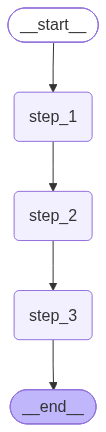

In [30]:
graph

In [34]:
try:
    print("▶️ Running graph: Please manually interrupt during Step 2...")
    graph.invoke({"input": "start"}, config={"configurable": {"thread_id": 'thread-1'}})
except KeyboardInterrupt:
    print("❌ Kernel manually interrupted (crash simulated).")

▶️ Running graph: Please manually interrupt during Step 2...
step 1 executed
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)
❌ Kernel manually interrupted (crash simulated).


In [35]:
list(graph.get_state_history({"configurable": {"thread_id": 'thread-1'}}))

[StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_2',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dbe9b-cc23-6ec6-8007-58490edc56fd'}}, metadata={'source': 'loop', 'step': 7, 'parents': {}}, created_at='2026-11-09T03:00:36.590534+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dbe9b-cc1e-6e97-8006-4abf0ff41d53'}}, tasks=(PregelTask(id='1a7b1ead-4756-40e7-93d4-bc22ed0c7e58', name='step_2', path=('__pregel_pull', 'step_2'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'input': 'start', 'step1': 'done'}, next=('step_1',), config={'configurable': {'thread_id': 'thread-1', 'checkpoint_ns': '', 'checkpoint_id': '1f1dbe9b-cc1e-6e97-8006-4abf0ff41d53'}}, metadata={'source': 'loop', 'step': 6, 'parents': {}}, created_at='2026-11-09T03:00:36.588480+00:00', parent_config={'configurable': {'thread_id': 'thread-1', 'checkp

In [36]:
# 6. Re-run to show fault-tolerant resume
print("\n🔁 Re-running the graph to demonstrate fault tolerance...")
final_state = graph.invoke(None, config={"configurable": {"thread_id": 'thread-1'}})
print("\n✅ Final State:", final_state)


🔁 Re-running the graph to demonstrate fault tolerance...
⏳ Step 2 hanging... now manually interrupt from the notebook toolbar (STOP button)


KeyboardInterrupt: 